# 05 — Második intelligenciaréteg: tematikus kategorizálás / Layer 2: thematic categorisation

HU: Az első réteg megmondja, **milyen** egy mondat (negatív / semleges / pozitív). A második réteg két szinten
mondja meg, **miről** és **pontosan mi miatt**:

```
mondat ──► [1. réteg] szentiment (B)              → negatív / semleges / pozitív
       ──► [2/a] aspektus-osztályozó (HRAST, BERT) → MIRŐL szól?   pl. bathroom
       ──► [2/b] altémák (beágyazás + fürtözés)    → MI A GOND?    pl. „nincs meleg víz”
```

| # | Lépés / Step | Mérés / Measurement | Dolgozat / Thesis |
|---|---|---|---|
| 1 | 2/a tanítás a HRAST-on / training on HRAST | aspektusonkénti F1 a HRAST-teszten, vs. kulcsszólista | 3.4, 3.5 |
| 2 | 2/a alkalmazás a Booking-mondatokra / applying to Booking | egyezés a kulcsszólistával | 3.5 |
| 3 | 2/b altémák aspektusonként / subtopics per aspect | NPMI-koherencia, diverzitás, stabilitás (ARI) | 3.4, 3.5 |
| 4 | Panasztérkép / complaint map | lift szegmensenként | 3.5 |
| 5 | Kézi ellenőrzés / manual check | témánkénti pontosság | 3.5 |

**Előfeltétel / Prerequisites:** a (B) modell (`results/models/approach_b_hrast`), a HRAST CSV a `data/raw/hrast/`
mappában, és `pip install sentence-transformers umap-learn`.
**Elemzési egység / Analysis unit:** tagmondat, a dicséret- és panaszmezőből KÜLÖN bontva / clause, split SEPARATELY
from the praise and complaint fields. GPU ajánlott (a 2/a tanítás kb. 10–15 perc).

## 1. Környezet és adatok / Environment and data

In [1]:
# HU: A notebooks/ mappából futunk, ezért a szülőmappát a path-hoz adjuk (src csomag).
# EN: We run from the notebooks/ folder, so the parent folder is added to the path (src package).
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import set_seed
from src.config import CFG, PATHS, SENTIMENT_COLORS, INK, APPROACHES, apply_plot_style
from src import data_loading as dl
from src import preprocessing as pp
from src import evaluation as ev
from src import descriptives as ds
from src import aspects as asp
from src import aspect_model as am
from src import topic_modeling as tm
from src import pipeline

# HU: Reprodukálhatóság + egységes ábrastílus. / EN: Reproducibility + uniform figure style.
set_seed()
PATHS.ensure()
apply_plot_style()
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 170)

# HU: ELEMZÉSI EGYSÉGEK: a dicséret- és a panaszmezőt KÜLÖN bontjuk tagmondatokra (pont, pontosvessző,
#     "but / however / although" mentén), így a kettő nem olvad egy "mondatba". A dicséretmezőben a
#     vesszős felsorolásokat is szétbontjuk (CFG.split_praise_lists). Minden egységre lefut a
#     (B) modell is (kb. 5–10 perc, darabolva, folytatható).
# EN: ANALYSIS UNITS: the praise and the complaint field are split into clauses SEPARATELY (at full stops,
#     semicolons, "but / however / although"), so the two never merge into one "sentence". In the praise
#     field comma enumerations are split too (CFG.split_praise_lists). The (B) model also runs on every
#     unit (about 5–10 min, chunked, resumable).
from src import bert_labelling as bl
meta = ds.prepare_star_rating(dl.read_frame(pipeline.LABELLED))
units = pp.build_field_units(meta)
scorer_b = bl.TransformerScorer(str(PATHS.models / "approach_b_hrast"))
sent = bl.predict_units(units, "", "B", cache_name="B_field_units", scorer=scorer_b)

meta_cols = ["review_id", "score", "label_final", "accommodation_type", "accommodation_country",
             "guest_type", "accommodation_star_rating"]
sent = sent.merge(meta[[c for c in meta_cols if c in meta.columns]], on="review_id", how="left")
dl.write_frame(sent, PATHS.labels / "field_units_B")
print(f"{len(sent):,} units from {sent['review_id'].nunique():,} reviews")

# HU: Mezőpolaritás × (B)-címke: mennyire ért egyet a modell a vendég saját besorolásával?
# EN: Field polarity × (B) label: how far does the model agree with the guest's own classification?
display(pd.crosstab(sent["field_polarity"], sent["B_label"], normalize="index").round(3))

21:24:29 | INFO    | src.preprocessing | Field units: 1100650 from 203079 reviews | by field: {'positive': 827008, 'negative': 273642}
21:24:43 | INFO    | src.bert_labelling | Loading model: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\results\models\approach_b_hrast (device: cuda, fp16: True)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

21:24:44 | INFO    | src.bert_labelling | Model type: 3class | labels: ['negative', 'neutral', 'positive']


1,100,650 units from 203,079 reviews


B_label,negative,neutral,positive
field_polarity,,,
negative,0.740,0.079,0.181
positive,0.067,0.049,0.884


## 2. 2/a — Aspektus-osztályozó a HRAST-on / Aspect classifier on HRAST

HU: Többcímkés BERT: aspektusonként egy igen/nem döntés (szigmoid). A ritka aspektusok nagyobb súlyt kapnak
(`pos_weight`), a döntési küszöböt aspektusonként a **validációs** halmazon hangoljuk, a végső mérés a **teszthalmazon**
történik — és ugyanott mérjük a kulcsszólistát is (alapvonal).

EN: Multi-label BERT: one yes/no decision per aspect (sigmoid). Rare aspects get a larger weight (`pos_weight`), the
decision threshold is tuned per aspect on the **validation** set, the final measurement is on the **test** set — where
the keyword list (baseline) is measured too.

In [2]:
hrast_raw = dl.load_hrast_raw()
asp_data, ASPECTS = am.prepare_hrast_aspects(hrast_raw)
counts = asp_data[ASPECTS].sum().sort_values(ascending=False).to_frame("sentences")
counts["share"] = (counts["sentences"] / len(asp_data)).round(4)
display(counts); ev.save_table(counts, "05_hrast_aspect_counts")

21:24:46 | INFO    | src.data_loading | HRAST loaded: hrast.csv — 23113 rows, columns: ['id', 'review', 'Unnamed: 2', 'positive', 'negative', 'neutral', 'Clean', 'Comfort', 'Facilities/Amenities', 'Location', 'Restaurant (dinner)', 'Staff', 'View (Balcony)', 'Breakfast', 'Room', 'Pool', 'Beach', 'Bathroom/Shower (toilet)', 'Bar', 'Bed', 'Parking', 'Noise', 'Reception-checkin', 'Lift', 'Value for money', 'Wi-Fi', 'Generic', 'Aspect']
21:24:46 | INFO    | src.aspect_model | HRAST aspect data: 23105 sentences, 21 aspects | without aspect: 0.0%


,sentences,share
room,5004,0.2166
location,4727,0.2046
staff,3800,0.1645
cleanliness,2926,0.1266
facilities,2923,0.1265
comfort,2561,0.1108
breakfast,2539,0.1099
bathroom,2344,0.1014
generic,1973,0.0854
noise,1604,0.0694


21:24:46 | INFO    | src.evaluation | Table saved: 05_hrast_aspect_counts.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_hrast_aspect_counts.csv')

Aspect model already trained — loading the saved test results.


,precision,recall,f1,support
room,0.7927,0.7906,0.7917,769
location,0.9348,0.9556,0.9451,675
staff,0.9193,0.9597,0.9391,546
cleanliness,0.9417,0.9417,0.9417,446
facilities,0.8479,0.8064,0.8266,470
comfort,0.8282,0.8258,0.8270,356
breakfast,0.9280,0.9704,0.9488,372
bathroom,0.9520,0.9242,0.9379,343
generic,0.7085,0.7864,0.7454,309
noise,0.9466,0.9323,0.9394,266


,support,keyword_precision,keyword_recall,keyword_f1,model_precision,model_recall,model_f1,f1_gain
aspect,,,,,,,,
room,769,0.5673,0.8986,0.6955,0.7927,0.7906,0.7917,0.0961
location,675,0.9282,0.9007,0.9143,0.9348,0.9556,0.9451,0.0308
staff,546,0.9022,0.8443,0.8723,0.9193,0.9597,0.9391,0.0668
facilities,470,0.5340,0.3511,0.4236,0.8479,0.8064,0.8266,0.4030
cleanliness,446,0.9332,0.7825,0.8512,0.9417,0.9417,0.9417,0.0905
breakfast,372,0.8589,0.9489,0.9017,0.9280,0.9704,0.9488,0.0471
bathroom,343,0.8963,0.9067,0.9014,0.9520,0.9242,0.9379,0.0364
noise,266,0.9755,0.7481,0.8468,0.9466,0.9323,0.9394,0.0926
value_for_money,136,0.6788,0.6838,0.6813,0.6894,0.8162,0.7475,0.0662


21:24:47 | INFO    | src.evaluation | Figure saved: 05_aspect_keyword_vs_model.png


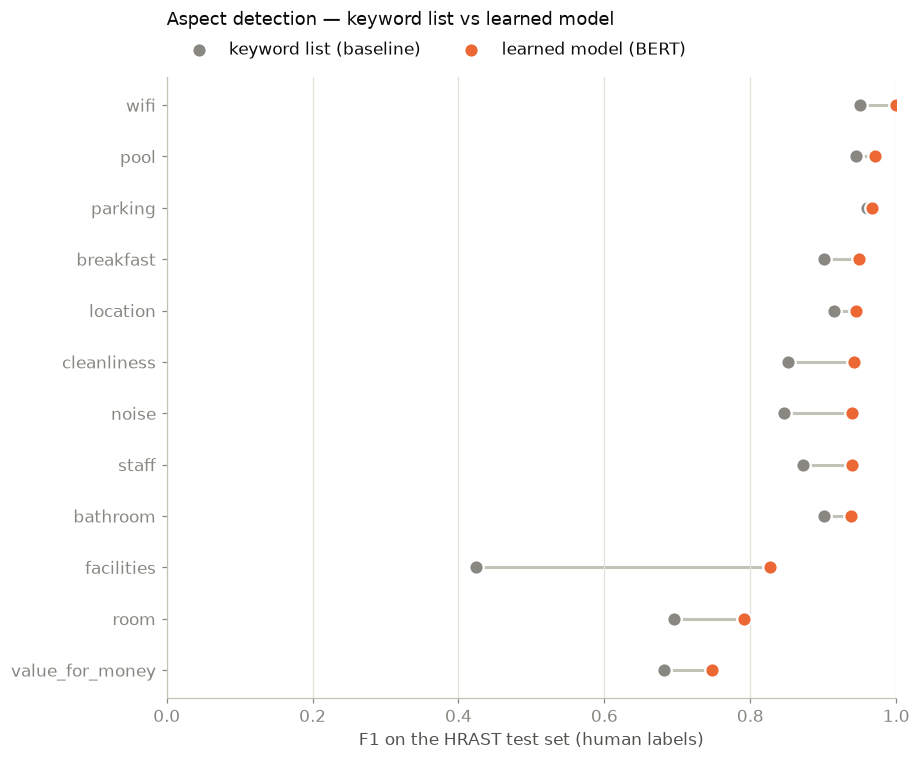

Mean F1 on the shared aspects — keyword: 0.829 | model: 0.913


In [3]:
# HU: Ha a modell már elkészült, nem tanítjuk újra (a mentett teszteredményt töltjük be).
# EN: If the model already exists it is not retrained (the saved test results are loaded).
if not (am.DEFAULT_MODEL_DIR / "thresholds.json").exists():
    result = am.train_aspect_model(asp_data, ASPECTS)
    report, comparison = result["test_report"], result["keyword_comparison"]
    ev.save_table(report, "05_aspect_model_test_report")
    ev.save_table(comparison, "05_aspect_keyword_vs_model")
else:
    print("Aspect model already trained — loading the saved test results.")
    report = pd.read_csv(PATHS.tables / "05_aspect_model_test_report.csv", index_col=0)
    comparison = pd.read_csv(PATHS.tables / "05_aspect_keyword_vs_model.csv", index_col=0)

display(report)
display(comparison)
am.plot_keyword_vs_model(comparison, save_as="05_aspect_keyword_vs_model"); plt.show()
print(f"Mean F1 on the shared aspects — keyword: {comparison['keyword_f1'].mean():.3f} | "
      f"model: {comparison['model_f1'].mean():.3f}")

## 3. 2/a alkalmazása a Booking-mondatokra / Applying 2/a to the Booking sentences

HU: Darabolt, folytatható futás (mint a címkézésnél). Itt nincs emberi címke, ezért a kulcsszólistával való
**egyezést** mérjük (konzisztencia), nem a pontosságot.
EN: Chunked, resumable run (as in labelling). There is no human label here, so we measure **agreement** with the
keyword list (consistency), not accuracy.

In [4]:
sent_asp = am.predict_aspects(sent, cache_name="aspects_field_units")
dl.write_frame(sent_asp, PATHS.labels / "field_units_aspects")
ASPECT_NAMES = am.aspect_names_in(sent_asp)

share = sent_asp[[f"asp_{a}" for a in ASPECT_NAMES]].mean().sort_values(ascending=False)
share.index = share.index.str.replace("asp_", "", regex=False)
display(share.round(4).to_frame("share of sentences"))
print(f"Sentences without any aspect: {(sent_asp['n_aspects'] == 0).mean():.1%}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

21:24:51 | INFO    | src.aspect_model | Aspects predicted for 1100650 sentences | without aspect: 4.1%


,share of sentences
location,0.2064
generic,0.1895
staff,0.1603
room,0.1425
facilities,0.0985
comfort,0.0921
breakfast,0.0921
cleanliness,0.0854
bathroom,0.0451
bed,0.0446


Sentences without any aspect: 4.1%


,mentions,mention_share,negative,neutral,positive,neg_lift,pos_lift
aspect,,,,,,,
lift,5971,0.0054,0.7503,0.0628,0.1869,3.2001,0.2637
bathroom,49626,0.0451,0.5162,0.0641,0.4197,2.2018,0.5921
wifi,6948,0.0063,0.5105,0.0535,0.4360,2.1773,0.6150
noise,37444,0.0340,0.4959,0.0283,0.4759,2.1149,0.6713
facilities,108410,0.0985,0.3781,0.0786,0.5433,1.6126,0.7665
reception,34296,0.0312,0.3407,0.0585,0.6008,1.4533,0.8475
value_for_money,37771,0.0343,0.3202,0.0731,0.6067,1.3658,0.8559
parking,17674,0.0161,0.3182,0.0598,0.6220,1.3569,0.8775
bed,49121,0.0446,0.2783,0.0400,0.6817,1.1868,0.9617


21:24:54 | INFO    | src.evaluation | Table saved: 05_aspect_sentiment_model.csv
21:24:54 | INFO    | src.evaluation | Figure saved: 05_aspect_sentiment_model.png


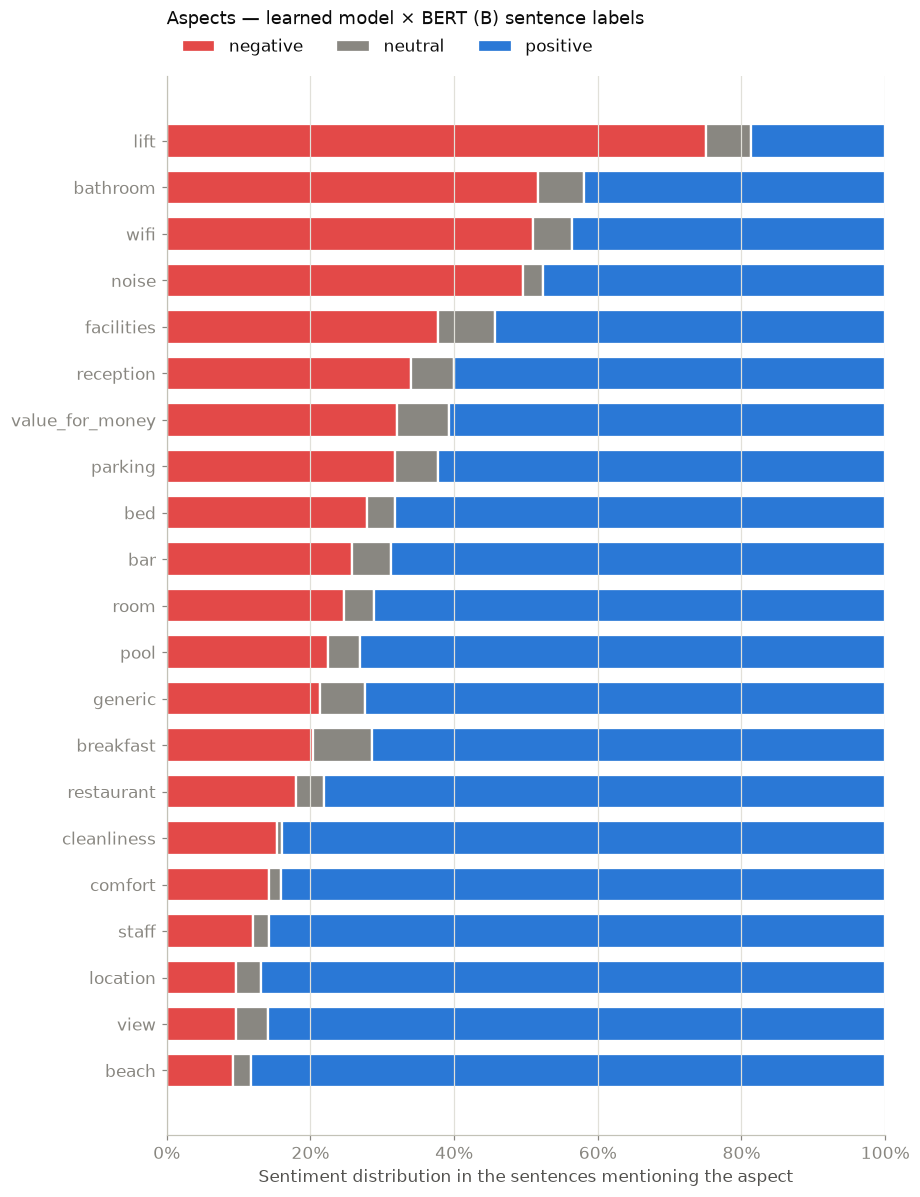

,share_model,share_keyword,agreement,cohen_kappa
aspect,,,,
location,0.2068,0.1498,0.9266,0.7510
staff,0.1615,0.1032,0.9300,0.6973
room,0.1419,0.1861,0.8873,0.5903
facilities,0.0965,0.0566,0.9046,0.3288
breakfast,0.0910,0.0935,0.9673,0.8049
cleanliness,0.0838,0.0759,0.9869,0.9109
bathroom,0.0453,0.0438,0.9874,0.8520
noise,0.0352,0.0283,0.9911,0.8547
value_for_money,0.0349,0.0305,0.9852,0.7669


21:24:56 | INFO    | src.evaluation | Table saved: 05_aspect_keyword_agreement_booking.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_aspect_keyword_agreement_booking.csv')

In [5]:
# HU: Aspektus × szentiment a TANULT aspektusokkal (vö. 04-es notebook: kulcsszavas változat).
# EN: Aspect × sentiment with the LEARNED aspects (cf. notebook 04: keyword version).
aspect_sent = asp.aspect_sentiment_table(sent_asp, label_col="B_label", aspects=ASPECT_NAMES,
                                         prefix="asp_", min_count=100)
display(aspect_sent); ev.save_table(aspect_sent, "05_aspect_sentiment_model")
asp.plot_aspect_sentiment(aspect_sent, "Aspects — learned model × BERT (B) sentence labels",
                          save_as="05_aspect_sentiment_model"); plt.show()

agreement = am.keyword_agreement(sent_asp.sample(min(50_000, len(sent_asp)), random_state=CFG.random_seed))
display(agreement); ev.save_table(agreement, "05_aspect_keyword_agreement_booking")

## 4. 2/b — Altémák aspektusonként / Subtopics per aspect

HU: A választott szentimentű (alapból **negatív**) mondatokon minden aspektusra külön témamodell: Sentence-BERT
beágyazás → UMAP → HDBSCAN → c-TF-IDF. A dicséretek altémáihoz állítsd `SENTIMENT = "positive"`-ra, és futtasd
újra innen (a fájlnevek a szentimentet is tartalmazzák).
EN: On sentences of the chosen sentiment (**negative** by default) a separate topic model per aspect: Sentence-BERT
embedding → UMAP → HDBSCAN → c-TF-IDF. For the subtopics of praise set `SENTIMENT = "positive"` and re-run from here
(file names include the sentiment).

In [6]:
SENTIMENT = "positive"
# HU: Az altéma-futás verziója (CFG.topic_version): minden alábbi kimenet nevében szerepel, így egy új
#     paraméterezés nem írja felül a korábbi (pl. v1) táblákat, ábrákat és kézi ellenőrzést.
# EN: Version of the subtopic run (CFG.topic_version): part of every output name below, so a new
#     parameter set does not overwrite earlier (e.g. v1) tables, figures and the manual check.
TAG = f"{SENTIMENT}_{CFG.topic_version}"
# HU: Kettős szűrés: a vendég a PANASZ-mezőbe írta, ÉS a (B) modell is negatívnak olvassa
#     (így kiesnek a panaszmezőbe írt "nothing, all perfect" típusú egységek).
# EN: Double filter: the guest wrote it into the COMPLAINT field AND the (B) model also reads it as
#     negative (this drops "nothing, all perfect" type units written into the complaint field).
subset = sent_asp[(sent_asp["field_polarity"] == SENTIMENT) & (sent_asp["B_label"] == SENTIMENT)
                  & (sent_asp["n_aspects"] > 0)].reset_index(drop=True)
print(f"{len(subset):,} {SENTIMENT} units with at least one aspect")

embeddings = tm.embed_sentences(subset["sentence"], cache_name=f"emb_{SENTIMENT}_units")

# HU: NEM-PANASZ egységek kiszűrése ("nothing", "no complaints", "all was perfect", "not the hotel's
#     fault"). A beágyazás a szűrés ELŐTT készül, így a cache érvényes marad; a sorokat utána
#     választjuk ki mindkettőből. Csak a negatív oldalon alkalmazzuk.
# EN: Remove NON-COMPLAINT units ("nothing", "no complaints", "all was perfect", "not the hotel's
#     fault"). The embedding is made BEFORE filtering, so the cache stays valid; rows are selected from
#     both afterwards. Applied on the negative side only.
if SENTIMENT == "negative":
    junk = pp.non_complaint_mask(subset["sentence"]).to_numpy()
    removed = subset.loc[junk, "sentence"].str.lower().str.strip(" .!").value_counts()
    print(f"Non-complaint units removed: {junk.sum():,} ({junk.mean():.1%})")
    display(removed.head(15).to_frame("count"))
    ev.save_table(removed.head(200).to_frame("count"), f"05_{TAG}_removed_non_complaints")
    subset, embeddings = subset.loc[~junk].reset_index(drop=True), embeddings[~junk]
print(f"{len(subset):,} units | embeddings: {embeddings.shape}")

714,792 positive units with at least one aspect


21:24:59 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
21:24:59 | WARNING | huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
21:24:59 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json?%2Fsentence-transformers%2Fall-MiniLM-L6-v2%2Fresolve%2Fmain%2Fmodules.json=&etag=%22952a9b81c0bfd99800fabf352f69c7ccd46c5e43%22 "HTTP/1.1 200 OK"
21:24:59 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
21:24:59 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transform

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

21:25:01 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
21:25:01 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
21:25:01 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/video_preprocessor_config.json "HTTP/1.1 404 Not Found"
21:25:01 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
21:25:01 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
21:25:01 | INFO    | httpx | HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-Mini

714,792 units | embeddings: (714792, 384)


c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
21:26:03 | INFO    | src.topic_modeling | Topics: 31 | noise 30.5% -> 5.9% | NPMI -0.042 | diversity 0.787


,value
n_sentences,30000.0000
n_topics,31.0000
n_topics_before_merge,31.0000
n_merges,0.0000
min_cluster_size,300.0000
giant_cluster_retries,0.0000
noise_share_before,0.3052
noise_share_after,0.0591
mean_coherence_npmi,-0.0421
topic_diversity,0.7871


,topic,size,share,label,top_terms,coherence_npmi,examples,merged_from
0,0,2268,0.075600,breakfast / breakfast good / good breakfast,"breakfast, breakfast good, good breakfast, good, delicious, great breakfast, breakfast great, breakfast excellent, g...",-0.083200,Breakfast was very nice || breakfast was very nice || Breakfast was very nice,
1,1,1926,0.064200,station / walk / close,"station, walk, close, city, train, town, centre, train station, walking, bus",0.285815,Good location next to the metro and train station (10 min walk) || Excellent location with a 10 minute walk into the...,
2,2,2048,0.068267,staff / friendly / helpful,"staff, friendly, helpful, staff friendly, friendly staff, friendly helpful, helpful staff, staff helpful, desk, kind",0.150919,the staff was so friendly and helpful || The staff was so friendly and helpful || staff very friendly,
3,3,1522,0.050733,recommend / located / hotels,"recommend, located, hotels, hostel, location, motel, beautiful, great, best, nice",-0.211546,The hotel is in a great location || The hotel has a great location || The hotel is wonderfully situated,
4,4,1211,0.040367,restaurants / restaurant / shops,"restaurants, restaurant, shops, close, bar, nearby, food, shopping, supermarket, bars",0.034237,nearby shopping and restaurants || Restaurants and shop nearby || Near restaurants and shops,
5,5,1089,0.036300,host / reception / hosts,"host, reception, hosts, welcome, helpful, friendly, reception staff, welcoming, family, feel",-0.085299,the host was always very pleasant and helpful || Our hosts were very welcoming || The host was friendly and helpful,
6,6,1020,0.034000,quiet / accommodation / noise,"quiet, accommodation, noise, peaceful, cozy, atmosphere, quiet location, relaxing, night, comfortable",-0.188672,"Very quiet place || Perfect location, quiet || Perfect location, quiet",
7,7,1048,0.034933,experience / needed / perfect,"experience, needed, perfect, great, nothing, thank, service, view, loved, nice",-0.242210,Everything was great || Everything was great || Everything was great,
8,8,752,0.025067,pool / swimming / swimming pool,"pool, swimming, swimming pool, spa, gym, pool area, pools, nice, area, nice pool",0.055232,Pool was beautiful and relaxing || pool is very nice || The pool is nice,
9,9,1065,0.035500,room / spacious / room spacious,"room, spacious, room spacious, room comfortable, comfortable, rooms, room nice, view, room great, suite",-0.146302,The room was nice and spacious || The room was very spacious || the room was very spacious,


21:26:03 | INFO    | src.evaluation | Table saved: 05_positive_full2_topics_overview.csv
21:26:04 | INFO    | src.evaluation | Figure saved: 05_positive_full2_topics_overview.png


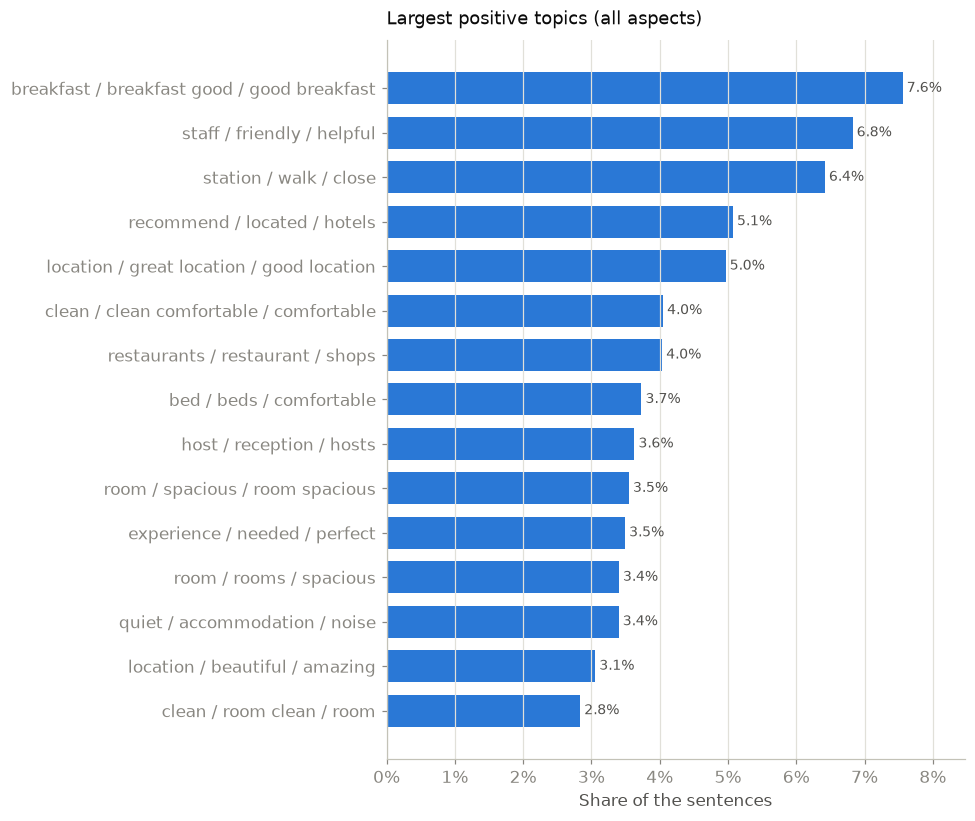

In [7]:
# HU: Áttekintő témamodell az összes ilyen mondaton (mintán) — aspektustól függetlenül.
# EN: Overview topic model on all such sentences (on a sample) — independent of the aspect.
rng = np.random.default_rng(CFG.random_seed)
overview_rows = np.sort(rng.choice(len(subset), size=min(30_000, len(subset)), replace=False))
overview = tm.fit_topics(subset["sentence"].iloc[overview_rows], embeddings[overview_rows])
display(pd.Series(overview.metrics).to_frame("value"))
display(overview.topic_info.head(20))
ev.save_table(overview.topic_info, f"05_{TAG}_topics_overview")
tm.plot_topic_sizes(overview.topic_info, f"Largest {SENTIMENT} topics (all aspects)", sentiment=SENTIMENT,
                    save_as=f"05_{TAG}_topics_overview"); plt.show()

### Finomság-vizsgálat / Granularity sweep

HU: Hány altémára bontsunk egy aspektust? A tapasztalat (v1, v2): egyetlen globális fürtméret nem jó minden
aspektusra — 1%-nál 19–21 apró, egymást átfedő altéma lett (pl. „rooms are small” és „the room was quite small” két
külön fürt), 3%-nál a fürdőszoba 18-ról **2** altémára ugrott (a HDBSCAN egy óriásfürtöt választott). Ezért (v3):
**finom fürtözés, majd a leghasonlóbb altémák összevonása** (BERTopic „topic reduction” elve), amíg legfeljebb
`CFG.subtopic_max_topics` marad, és nincs két `CFG.subtopic_merge_similarity` feletti hasonlóságú (közel-duplikátum)
téma. Az összevonás **átlagos kapcsolással** történik, és egy összevont altéma legfeljebb az aspektus
`CFG.subtopic_max_topic_share` részét (35%) teheti ki — enélkül (v3) „hógolyó” gyűjtőtémák keletkeztek (a zajnál a
forgalom, a zene és a szomszédok egyetlen 55%-os témává olvadt). A táblázat a három legnagyobb aspektuson mutatja a
lehetőségeket (`none` = nincs összevonás). Cél: kb.
**5–10 altéma**, a legnagyobb ≲ 50%, a koherencia (NPMI) ne romoljon. A UMAP aspektusonként egyszer fut (kb. 1–2 perc).

EN: How many subtopics should an aspect be split into? Experience (v1, v2): no single global cluster size suits every
aspect — at 1% there were 19–21 small, overlapping subtopics (e.g. "rooms are small" and "the room was quite small" as
two clusters), at 3% bathroom jumped from 18 to **2** subtopics (HDBSCAN picked one giant cluster). Hence (v3):
**fine clustering, then merging the most similar subtopics** (BERTopic "topic reduction" principle) until at most
`CFG.subtopic_max_topics` remain and no two topics exceed `CFG.subtopic_merge_similarity` (near-duplicates). The table
uses **average linkage**, and a merged subtopic may not exceed `CFG.subtopic_max_topic_share` (35%) of the aspect —
without that (v3) "snowball" catch-all topics appeared (for noise, traffic, music and neighbours melted into one 55%
topic). The table shows the options on the three largest aspects (`none` = no merging). Goal: about **5–10 subtopics**, largest ≲ 50%,
no worse coherence (NPMI). UMAP runs once per aspect (about 1–2 min). Set `RUN_SWEEP = False` once the setting is chosen.

In [8]:
RUN_SWEEP = True
if RUN_SWEEP:
    flag_counts = {a: int(subset[f"asp_{a}"].sum()) for a in ASPECT_NAMES if a not in ("generic",)}
    sweep_aspects = sorted(flag_counts, key=flag_counts.get, reverse=True)[:3]
    sweeps = []
    for aspect in sweep_aspects:
        rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
        rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
            rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
        sweeps.append(tm.granularity_sweep(subset["sentence"].iloc[rows], embeddings[rows])
                        .reset_index().assign(aspect=aspect))
    sweep = pd.concat(sweeps, ignore_index=True).set_index(["aspect", "min_cluster_share", "max_topics"])
    display(sweep); ev.save_table(sweep, f"05_{TAG}_granularity_sweep")
print("Chosen subtopic settings:", tm.subtopic_params())

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
21:26:11 | INFO    | src.topic_modeling | Topics: 27 | noise 22.7% -> 3.2% | NPMI -0.267 | diversity 0.778
21:26:11 | INFO    | src.topic_modeling | Topics: 12 | noise 22.7% -> 3.2% | NPMI -0.089 | diversity 0.783
21:26:11 | INFO    | src.topic_modeling | Topics: 10 | noise 22.7% -> 3.2% | NPMI -0.084 | diversity 0.790
21:26:12 | INFO    | src.topic_modeling | Topics: 8 | noise 22.7% -> 3.2% | NPMI -0.093 | diversity 0.838
21:26:12 | INFO    | src.topic_modeling | Topics: 6 | noise 22.7% -> 3.2% | NPMI -0.072 | diversity 0.817
21:26:12 | INFO    | src.topic_modeling | Topics: 14 | noise 21.7% -> 3.2% | NPMI -0.139 | diversity 0.729
21:26:12 | INFO    | src.topic_modeling | Topics: 12 | noise 21.7% -> 3.2% | NPMI -0.090 | diversity 0.725
21:26:13 | INFO    | src.topic_modeling |

min_cluster_size  n_topics_before_merge  n_topics  noise_share_before  mean_coherence_npmi  topic_diversity  largest_topic_share
aspect   min_cluster_share max_topics                                                                                                                                  
location 0.01              none                      50                     27        27              0.2272              -0.2668           0.7778               0.1048
                           12                        50                     27        12              0.2272              -0.0890           0.7833               0.2592
                           10                        50                     27        10              0.2272              -0.0842           0.7900               0.2592
                           8                         50                     27         8              0.2272              -0.0933           0.8375               0.2592
                           6                         50                     27         6              0.2272              -0.0717           0.8167               0.3366
         0.02              none                     100                     14        14              0.2168              -0.1391           0.7286               0.1338
                           12                       100                     14        12              0.2168              -0.0902           0.7250               0.1400
                           10                       100                     14        10              0.2168              -0.0672           0.7500               0.3060
                           8                        100                     14         8              0.2168              -0.0829           0.7500               0.3060
                           6                        100                     14         6              0.2168              -0.0595           0.8000               0.3352
staff    0.01              none                      50                     32        32              0.2046              -0.3096           0.6467               0.1118
                           12                        50                     32        12              0.2046              -0.1969           0.7417               0.3330
                           10                        50                     32        10              0.2046              -0.1850           0.7200               0.3330
                           8                         50                     32         8              0.2046              -0.1693           0.7500               0.3330
                           6                         50                     32         6              0.2046              -0.1149           0.7667               0.3330
         0.02              none                     100                     15        15              0.2496              -0.1781           0.7000               0.1602
                           12                       100                     15        12              0.2496              -0.0961           0.6750               0.2214
                           10                       100                     15        10              0.2496              -0.1216           0.6900               0.3206
                           8                        100                     15         8              0.2496              -0.0864           0.7250               0.3206
                           6                        100                     15         6              0.2496              -0.1049           0.8167               0.3206
room     0.01              none                      50                     32        32              0.2560              -0.3147           0.6906               0.0894
                           12                        50                     32        12              0.2560              -0.1920           0.7500               0.2496
       

21:26:32 | INFO    | src.evaluation | Table saved: 05_positive_full2_granularity_sweep.csv


Chosen subtopic settings: {'min_cluster_share': 0.02, 'max_topics': 10, 'merge_similarity': 0.9, 'max_topic_share': 0.35, 'max_initial_share': 0.5}


21:26:32 | INFO    | src.topic_modeling | room             107550 sentences (model fitted on 5000)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
21:26:39 | INFO    | src.topic_modeling | Topics: 10 | noise 28.2% -> 1.8% | NPMI -0.171 | diversity 0.770
21:26:39 | INFO    | src.topic_modeling | location         191437 sentences (model fitted on 5000)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
21:26:46 | INFO    | src.topic_modeling | Topics: 10 | noise 26.2% -> 3.1% | NPMI -0.032 | diversity 0.800
21:26:46 | INFO    | src.topic_modeling | staff            145059 sentences (model fitted on 5000)
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.ve

,n_sentences,n_topics_before_merge,n_topics,min_cluster_size,giant_cluster_retries,noise_share_before,noise_share_after,mean_coherence_npmi,topic_diversity
aspect,,,,,,,,,
room,5000,14,10,100,0,0.2822,0.0184,-0.1709,0.77
location,5000,14,10,100,0,0.2622,0.0308,-0.0316,0.80
staff,5000,16,10,100,0,0.1630,0.0434,-0.1789,0.72
cleanliness,5000,15,10,100,0,0.1172,0.0024,-0.1412,0.76
facilities,5000,18,10,100,0,0.1790,0.0526,-0.1126,0.88
comfort,5000,13,10,100,0,0.1136,0.0056,-0.1686,0.62
breakfast,5000,31,10,50,1,0.2694,0.0048,-0.1566,0.74
bathroom,5000,16,10,100,0,0.2700,0.0044,-0.1457,0.73
noise,5000,15,10,100,0,0.3564,0.0094,-0.1498,0.80


21:28:56 | INFO    | src.evaluation | Table saved: 05_positive_full2_subtopic_quality.csv
21:28:56 | INFO    | src.evaluation | Table saved: 05_positive_full2_subtopics.csv


Main aspects: ['room', 'location', 'staff', 'cleanliness', 'facilities', 'comfort', 'breakfast', 'bathroom', 'noise', 'bed', 'reception', 'value_for_money', 'view', 'parking', 'pool', 'bar', 'restaurant', 'beach', 'wifi', 'lift']


21:29:00 | INFO    | src.evaluation | Figure saved: 05_positive_full2_subtopics_by_aspect.png


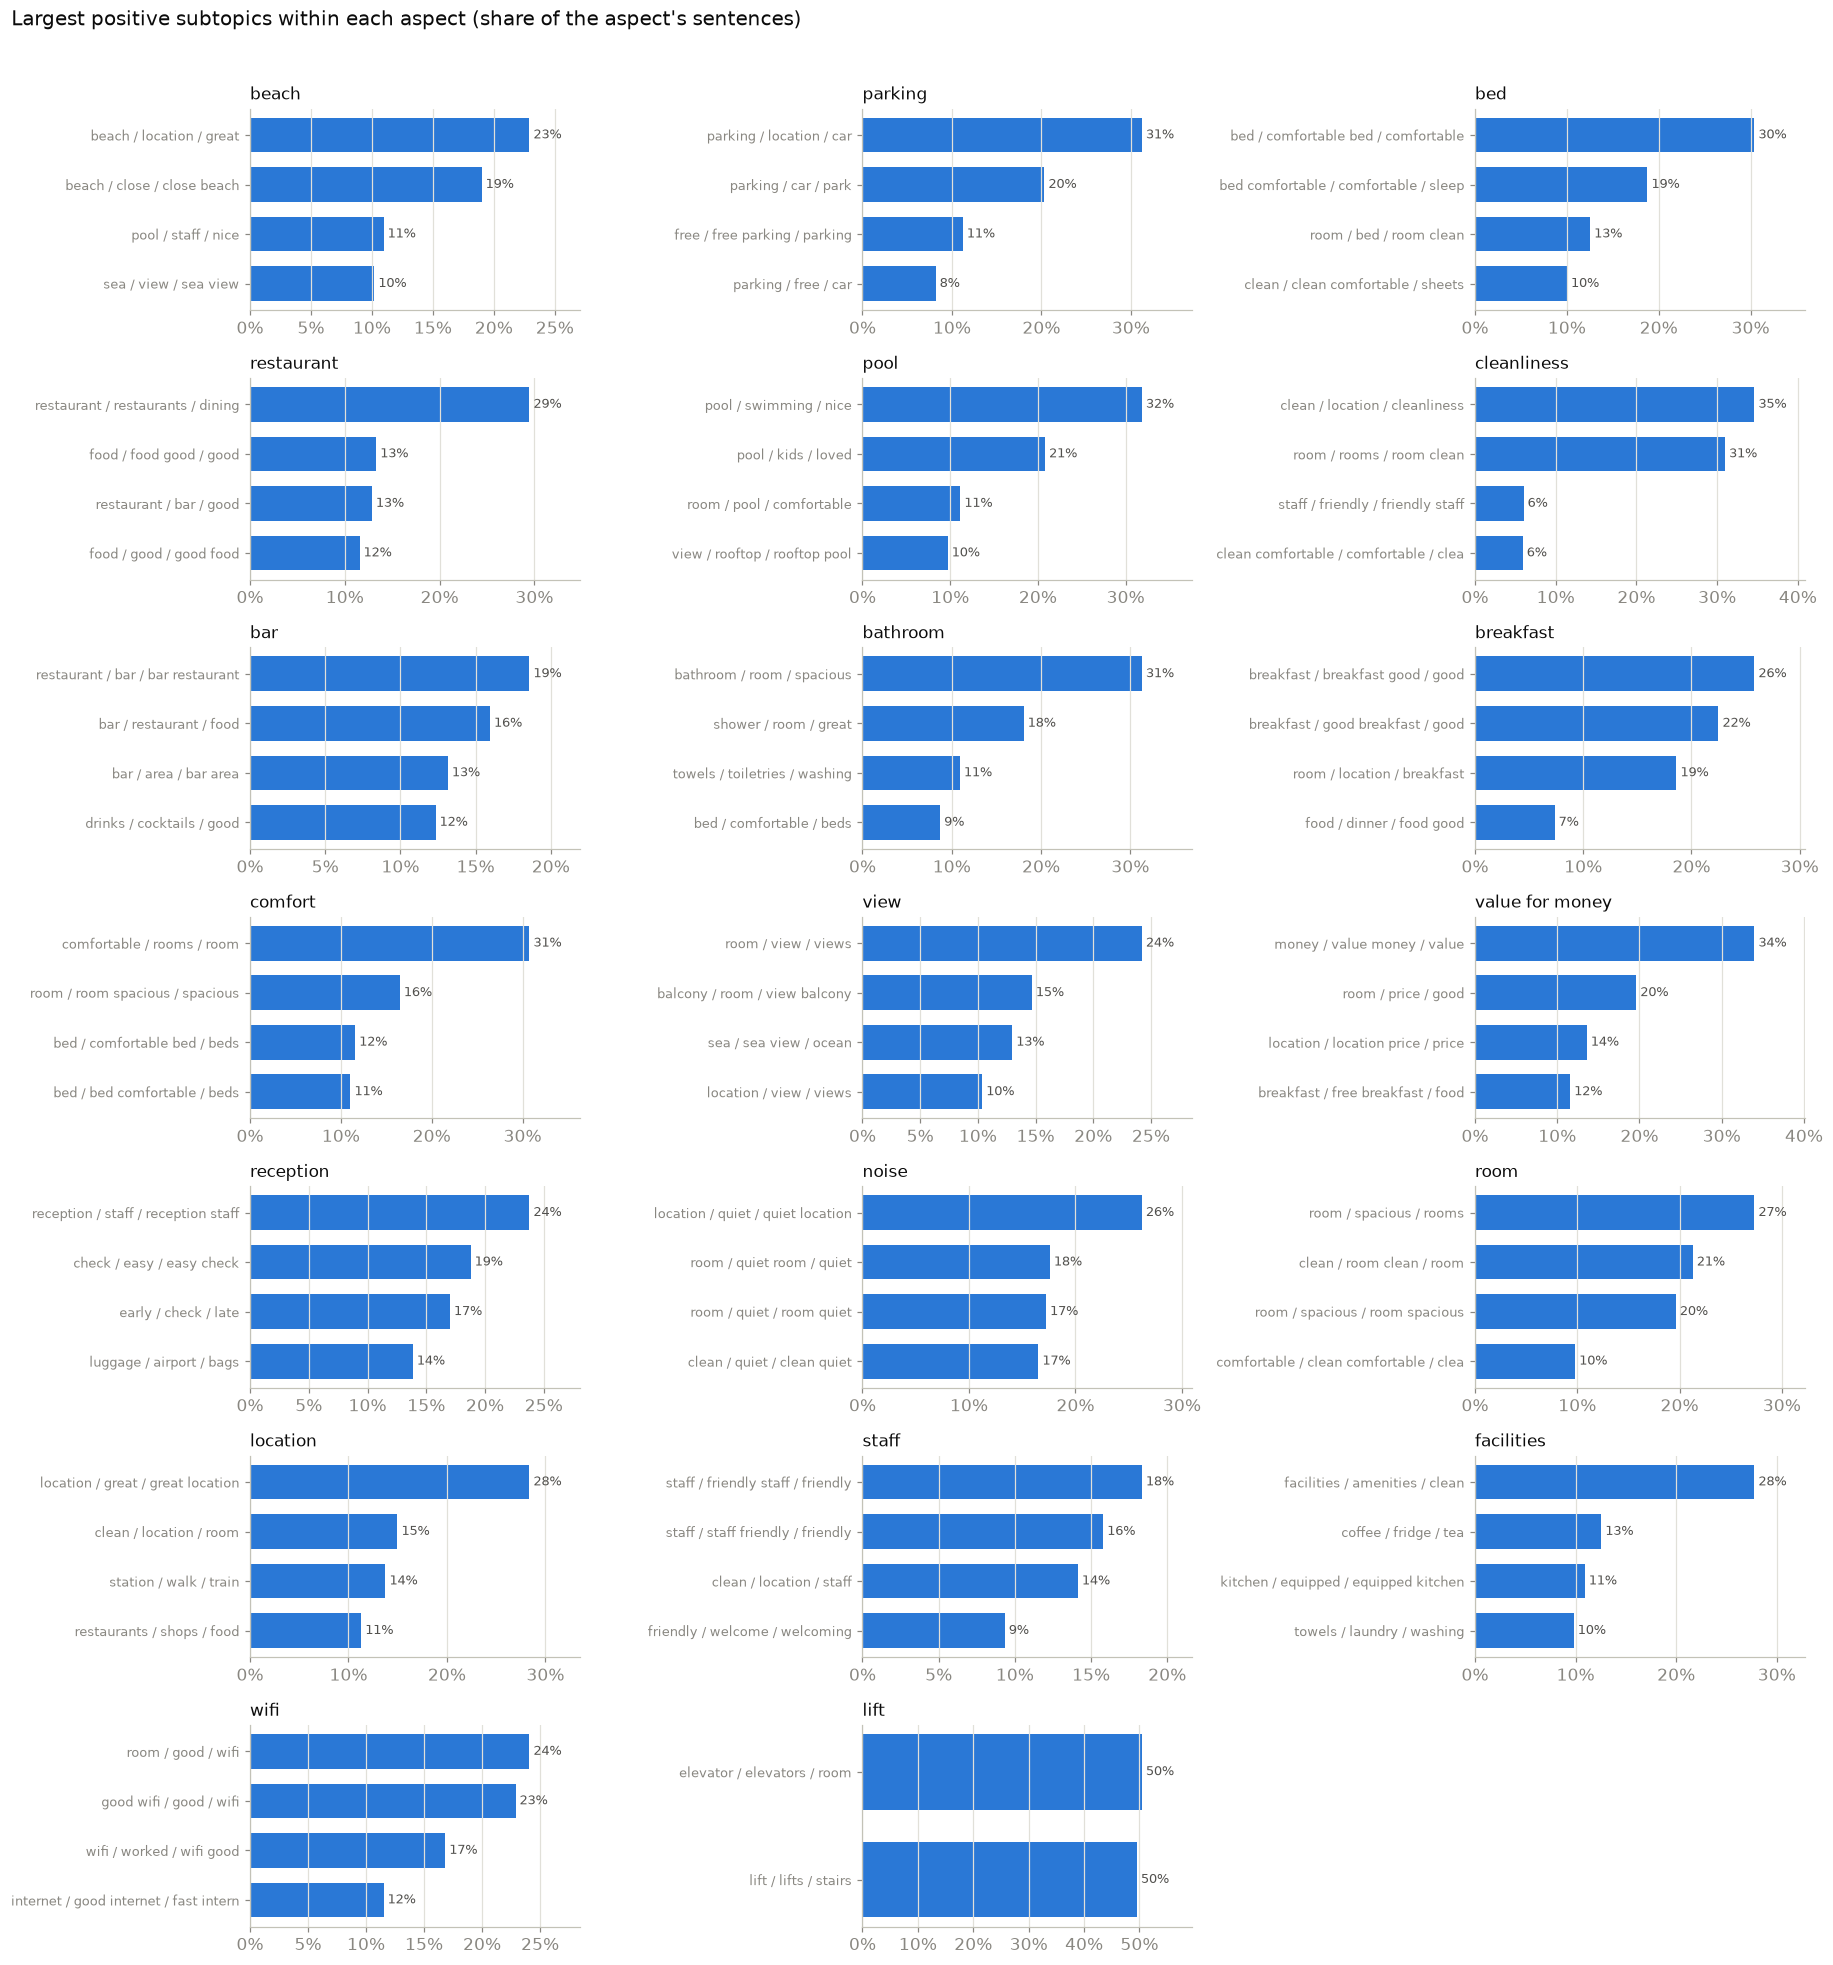

In [9]:
topic_table, assignments, topic_summary = tm.fit_subtopics_per_aspect(subset, embeddings, ASPECT_NAMES)
display(topic_summary)
ev.save_table(topic_summary, f"05_{TAG}_subtopic_quality")
# HU: A legtöbb mondatú, legalább egy altémát adó aspektusok. / EN: Aspects with most sentences and at least one subtopic.
MAIN_ASPECTS = (topic_summary[topic_summary["n_topics"] > 0]
                .sort_values("n_sentences", ascending=False).index.tolist())
print("Main aspects:", MAIN_ASPECTS)
ev.save_table(topic_table, f"05_{TAG}_subtopics")
dl.write_frame(assignments.assign(review_id=subset["review_id"].iloc[assignments["row"]].to_numpy(),
                                  sentence=subset["sentence"].iloc[assignments["row"]].to_numpy()),
               PATHS.labels / f"subtopic_assignments_{TAG}")

tm.plot_aspect_subtopics(topic_table, top_k=4, sentiment=SENTIMENT,
                         save_as=f"05_{TAG}_subtopics_by_aspect"); plt.show()

In [10]:
# HU: Olvasd el az altémákat a példamondatokkal! / EN: Read the subtopics with the example sentences!
for aspect in MAIN_ASPECTS[:4]:
    print(f"\n=== {aspect} ===")
    for _, r in topic_table[topic_table["aspect"] == aspect].head(6).iterrows():
        print(f"  [{r['topic']}] {r['label']}  ({r['share_within_aspect']:.0%}, NPMI {r['coherence_npmi']:.2f})")
        if r["merged_from"]:
            print(f"       merged from: {r['merged_from'][:150]}")
        print(f"       e.g. {r['examples'].split(' || ')[0][:150]}")


=== room ===
  [0] room / spacious / rooms  (27%, NPMI -0.05)
       merged from: room / rooms / spacious + bathroom / shower / room bathroom
       e.g. spacious and nice rooms
  [1] clean / room clean / room  (21%, NPMI -0.29)
       merged from: clean / clean room / rooms + room clean / clean / room
       e.g. Rooms very clean
  [2] room / spacious / room spacious  (20%, NPMI -0.10)
       merged from: room / view / room spacious + room / decorated / room great + room comfortable / comfortable / room
       e.g. The room was very spacious
  [3] comfortable / clean comfortable / clean  (10%, NPMI -0.32)
       e.g. Clean and comfortable
  [4] breakfast / staff / friendly  (5%, NPMI 0.13)
       e.g. Pleasant staff comfortable room good breakfast
  [5] cozy / air / warm  (4%, NPMI -0.52)
       e.g. Warm and comfortable room

=== location ===
  [0] location / great / great location  (28%, NPMI -0.27)
       merged from: location / great / excellent + great location / great / locatio

In [11]:
# HU: OPCIONÁLIS: beszédes nevek a dolgozatba (a témaszámokat a fenti listából vedd).
# EN: OPTIONAL: meaningful names for the thesis (take the topic numbers from the list above).
TOPIC_NAMES = {
    # ("bathroom", 0): "no hot water",
    # ("noise", 1): "thin walls / neighbours",
}
if TOPIC_NAMES:
    topic_table, assignments = tm.rename_topics(topic_table, assignments, TOPIC_NAMES)
    ev.save_table(topic_table, f"05_{TAG}_subtopics")

### Stabilitás / Stability

HU: Ugyanaz a modell három különböző véletlen kezdőértékkel a három legnagyobb aspektuson. A korrigált Rand-index
(ARI) 0,5 felett azt jelzi, hogy a témák nem a véletlen termékei.
EN: The same model with three different random seeds on the three largest aspects. An adjusted Rand index (ARI)
above 0.5 shows that the topics are not products of chance.

In [12]:
stability_rows = []
for aspect in MAIN_ASPECTS[:3]:
    rows = np.where(subset[f"asp_{aspect}"].to_numpy() == 1)[0]
    rows = np.sort(np.random.default_rng(CFG.random_seed).choice(
        rows, size=min(len(rows), CFG.topic_sample_per_aspect), replace=False))
    table = tm.topic_stability(subset["sentence"].iloc[rows], embeddings[rows], **tm.subtopic_params())
    stability_rows.append({"aspect": aspect, "mean_pairwise_ari": table.attrs["mean_pairwise_ari"],
                           "n_topics_per_seed": table["n_topics"].tolist()})
stability = pd.DataFrame(stability_rows).set_index("aspect").round(3)
display(stability); ev.save_table(stability, f"05_{TAG}_subtopic_stability")

c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
21:29:08 | INFO    | src.topic_modeling | Topics: 10 | noise 28.2% -> 1.8% | NPMI -0.171 | diversity 0.770
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
21:29:15 | INFO    | src.topic_modeling | Topics: 10 | noise 24.5% -> 1.4% | NPMI -0.148 | diversity 0.760
c:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
21:29:22 | INFO    | src.topic_modeling | Topics: 10 | noise 25.2% -> 1.4% | NPMI -0.146 | diversity 0.760
21:29:22 | INFO    | src.topic_modeling | S

,mean_pairwise_ari,n_topics_per_seed
aspect,,
room,0.826,"[10, 10, 10]"
location,0.653,"[10, 10, 10]"
staff,0.652,"[10, 10, 10]"


21:30:03 | INFO    | src.evaluation | Table saved: 05_positive_full2_subtopic_stability.csv


WindowsPath('C:/Users/seszt/Documents/BCE/7_felev/Szakdolgozat/THESIS/CODE/results/tables/05_positive_full2_subtopic_stability.csv')

## 5. Panasztérkép / Complaint map

HU: Egy aspektus altémáinak aránya szegmensenként, liftként: 1 felett az altéma az adott szegmensben gyakoribb,
mint átlagosan. Például: a szállodákban a „vékony fal” vagy az apartmanokban a „nincs meleg víz” a jellemzőbb?
Minden cellára arány-z-próba (szegmens vs. többi) Benjamini–Hochberg-korrekcióval. `*` = szignifikáns ÉS legalább 20%-os
eltérés (|lift − 1| ≥ 0,2), halvány = nem. Kis szegmensben a nagy lift is lehet véletlen, nagy mintán pedig egy 1,06-os
eltérés is szignifikáns — a dolgozatban csak a csillagos cellákat értelmezd. Színek: az átlagnál gyakoribb altéma a
szentiment színét kapja (panasz = piros, dicséret = kék), a ritkább szürke.
EN: Share of an aspect's subtopics per segment, as lift: above 1 the subtopic is more common in that segment than on
average. E.g.: is "thin walls" more typical in hotels, or "no hot water" in apartments?
A two-proportion z-test per cell (segment vs. rest) with Benjamini–Hochberg correction. `*` = significant AND at least a
20% difference (|lift − 1| ≥ 0.2), faded = not. In a small segment even a large lift can be chance, on a large sample even
1.06 is significant — interpret only the starred cells in the thesis. Colours: a subtopic more common than average gets
the sentiment colour (complaint = red, praise = blue), a rarer one grey.

21:30:04 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_room_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
14,Apartment,apartment / spacious apartment / apartment clean,6.591,2256,9118,0.0,True,True
6,ApartHotel,apartment / spacious apartment / apartment clean,3.998,715,4764,0.0,True,True
11,Apartment,comfortable / clean comfortable / clean,1.603,1558,9118,0.0,True,True
15,Apartment,balcony / terrace / room balcony,1.523,470,9118,0.0,True,True
39,Hostel,balcony / terrace / room balcony,1.450,143,2913,0.0,True,True
63,Resort,balcony / terrace / room balcony,1.426,162,3356,0.0,True,True
51,Motel,comfortable / clean comfortable / clean,1.413,566,3758,0.0,True,True
20,Bed and Breakfast,breakfast / staff / friendly,1.378,521,6606,0.0,True,True


21:30:05 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_room_by_accommodation_type.png


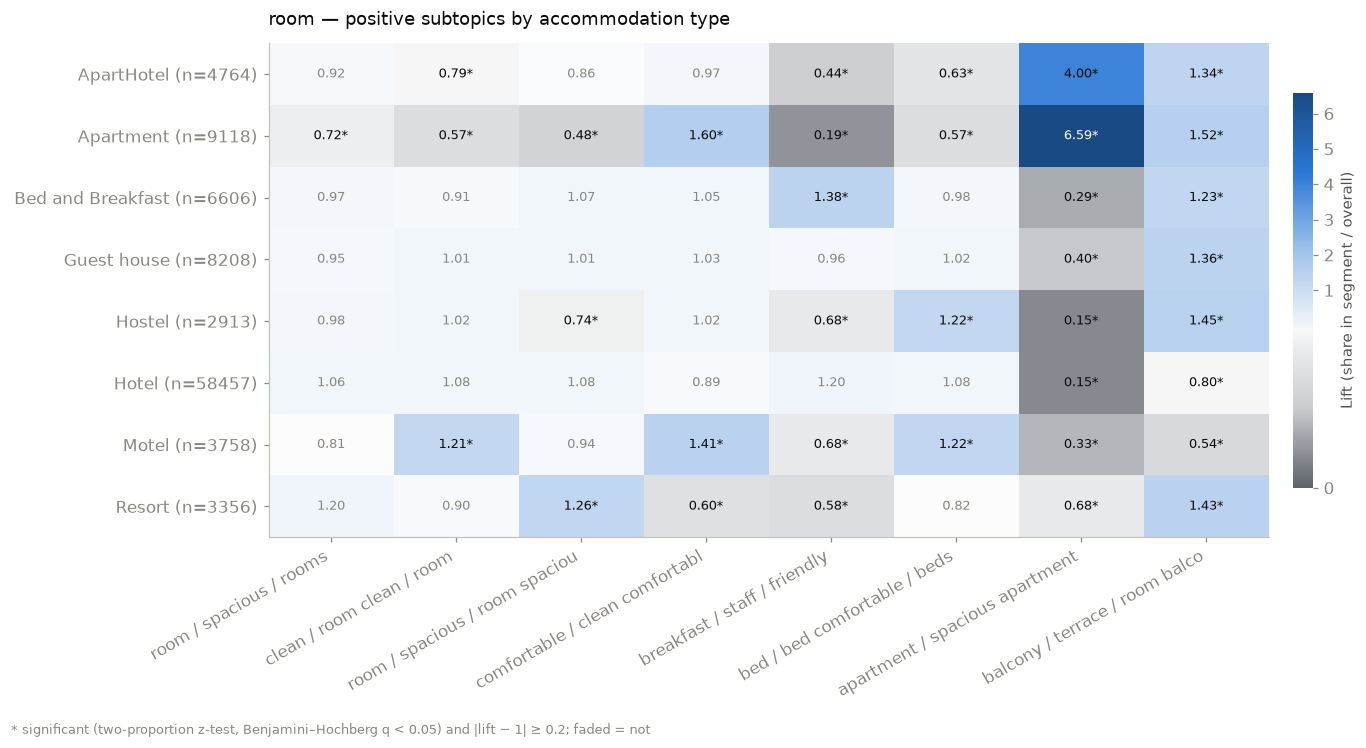

21:30:05 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_room_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
38,Spain,apartment / spacious apartment / apartment clean,2.727,417,4124,0.0,True,True
22,Greece,apartment / spacious apartment / apartment clean,2.343,269,3096,0.0,True,True
30,Italy,apartment / spacious apartment / apartment clean,1.609,457,7661,0.0,True,True
52,United Kingdom,breakfast / staff / friendly,1.377,1706,20949,0.0,True,True
6,Australia,apartment / spacious apartment / apartment clean,1.326,276,5612,0.0,True,True
40,Thailand,room / spacious / rooms,1.309,917,2874,0.0,True,True
57,United States of America,clean / room clean / room,1.247,3138,11741,0.0,True,True
61,United States of America,bed / bed comfortable / beds,1.241,804,11741,0.0,True,True


21:30:06 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_room_by_accommodation_country.png


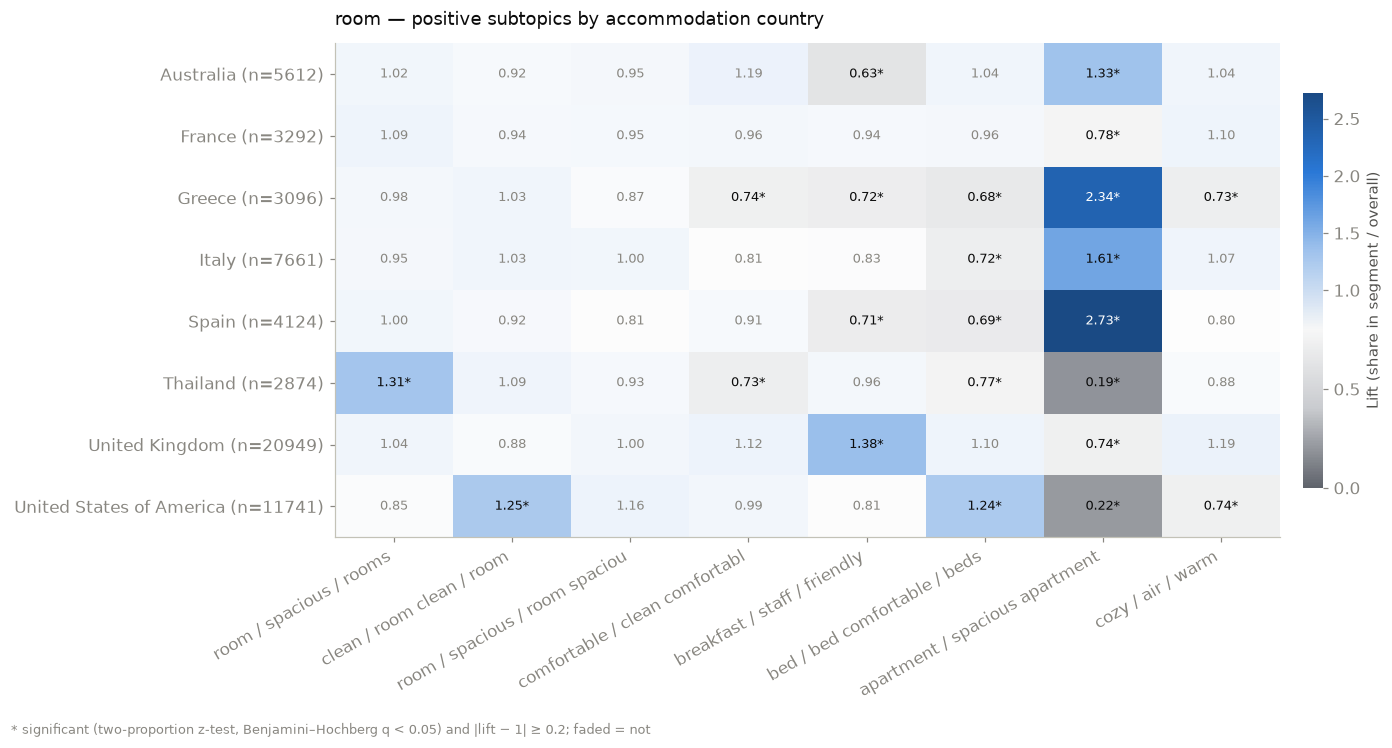

21:30:07 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_location_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
61,Resort,beach / pool / close beach,4.282,2068,5680,0.0,True,True
23,Bed and Breakfast,quiet / quiet location / area,1.723,495,9058,0.0,True,True
5,ApartHotel,beach / pool / close beach,1.588,1174,8693,0.0,True,True
53,Motel,beach / pool / close beach,1.495,650,5114,0.0,True,True
51,Motel,restaurants / shops / food,1.394,816,5114,0.0,True,True
46,Hotel,airport / shuttle / close airport,1.388,6301,96592,0.0,True,True
3,ApartHotel,restaurants / shops / food,1.307,1301,8693,0.0,True,True
31,Guest house,quiet / quiet location / area,1.306,549,13255,0.0,True,True


21:30:08 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_location_by_accommodation_type.png


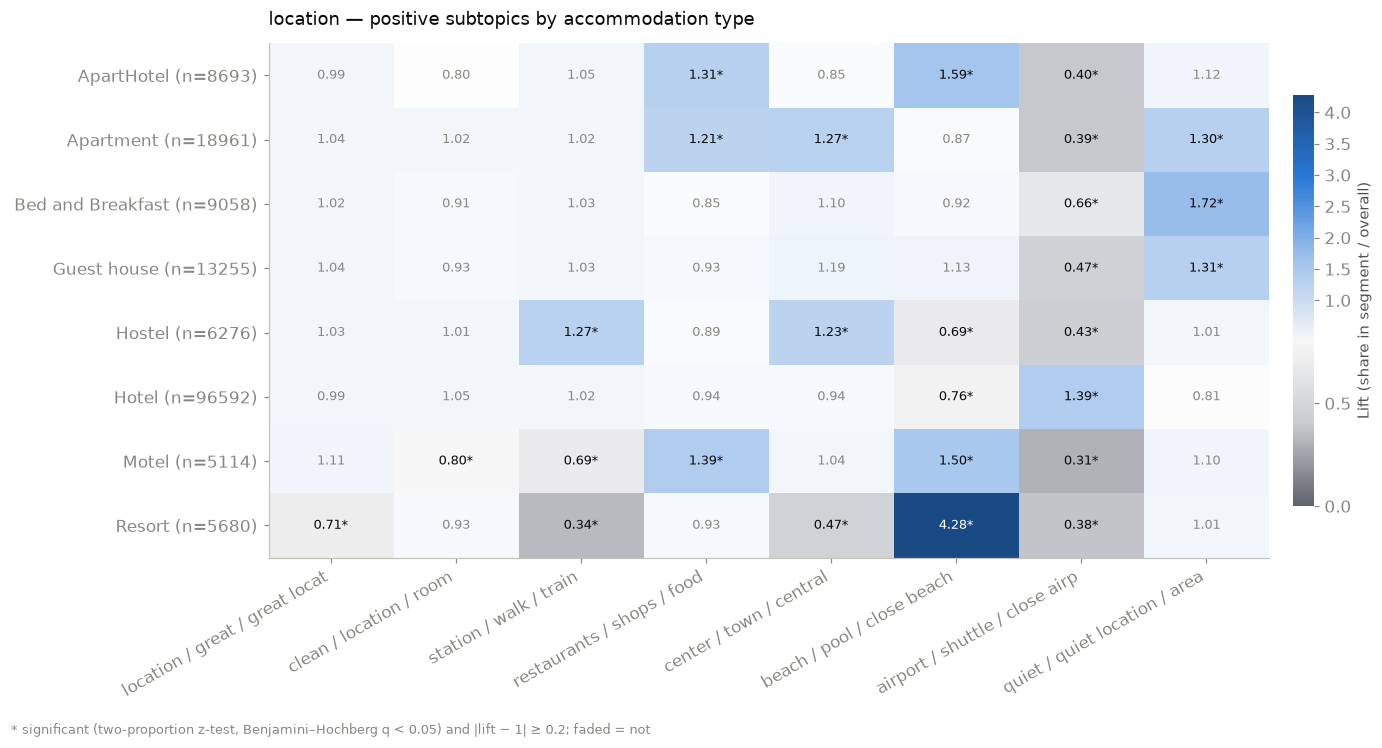

21:30:08 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_location_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
21,Greece,beach / pool / close beach,2.637,1284,6491,0.0,True,True
33,Japan,station / walk / train,1.966,1640,5511,0.0,True,True
5,Australia,beach / pool / close beach,1.560,985,8415,0.0,True,True
54,United Kingdom,airport / shuttle / close airport,1.546,1891,27953,0.0,True,True
45,Spain,beach / pool / close beach,1.496,981,8743,0.0,True,True
35,Japan,restaurants / shops / food,1.363,852,5511,0.0,True,True
3,Australia,restaurants / shops / food,1.360,1298,8415,0.0,True,True
25,Italy,station / walk / train,1.349,3206,15702,0.0,True,True


21:30:10 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_location_by_accommodation_country.png


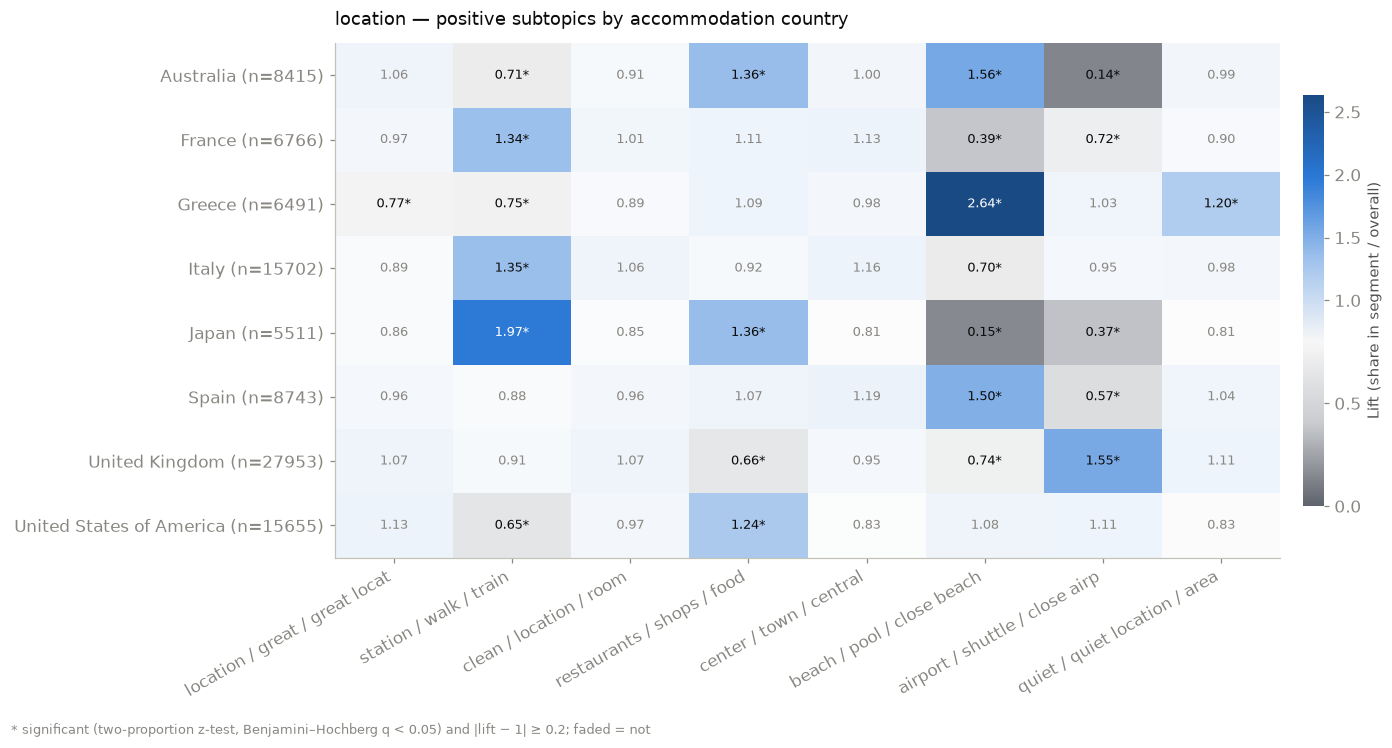

21:30:10 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_staff_by_accommodation_type.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
12,Apartment,host / hosts / communication,4.269,2998,8614,0.0,True,True
20,Bed and Breakfast,host / hosts / communication,3.014,2300,9359,0.0,True,True
28,Guest house,host / hosts / communication,2.546,2205,10625,0.0,True,True
15,Apartment,helped / help / luggage,1.799,942,8614,0.0,True,True
19,Bed and Breakfast,breakfast / food / good,1.528,1171,9359,0.0,True,True
31,Guest house,helped / help / luggage,1.443,932,10625,0.0,True,True
23,Bed and Breakfast,helped / help / luggage,1.387,789,9359,0.0,True,True
6,ApartHotel,reception / reception staff / receptionist,1.377,431,4256,0.0,True,True


21:30:11 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_staff_by_accommodation_type.png


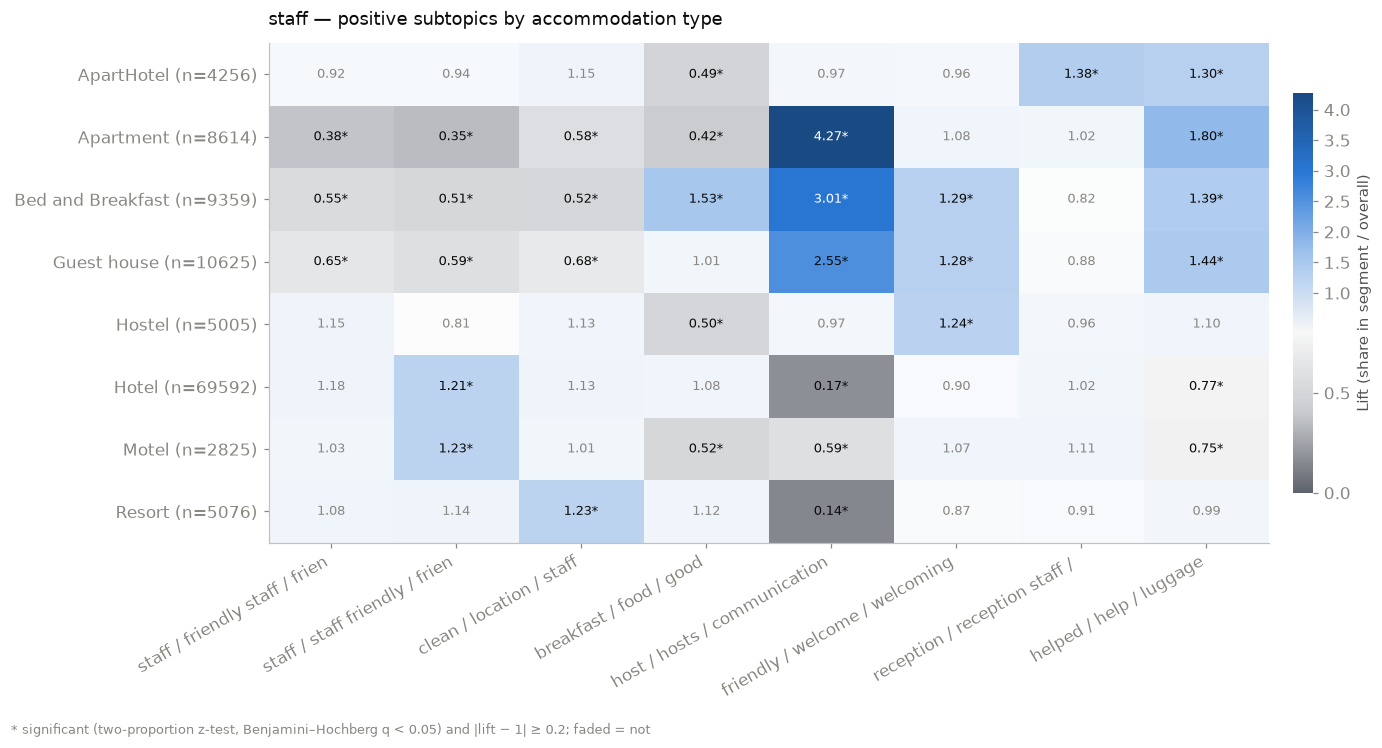

21:30:12 | INFO    | src.evaluation | Table saved: 05_positive_full2_map_staff_by_accommodation_country.csv


,segment,subtopic,lift,count,segment_n,q,significant,notable
23,Greece,helped / help / luggage,1.683,478,5066,0.0,True,True
19,Greece,host / hosts / communication,1.629,736,5066,0.0,True,True
31,Italy,helped / help / luggage,1.629,995,10894,0.0,True,True
27,Italy,host / hosts / communication,1.623,1577,10894,0.0,True,True
57,United States of America,staff / staff friendly / friendly,1.566,3326,10959,0.0,True,True
52,United Kingdom,breakfast / food / good,1.324,2458,21256,0.0,True,True
42,Thailand,clean / location / staff,1.313,671,3856,0.0,True,True
40,Thailand,staff / friendly staff / friendly,1.290,1129,3856,0.0,True,True


21:30:13 | INFO    | src.evaluation | Figure saved: 05_positive_full2_map_staff_by_accommodation_country.png


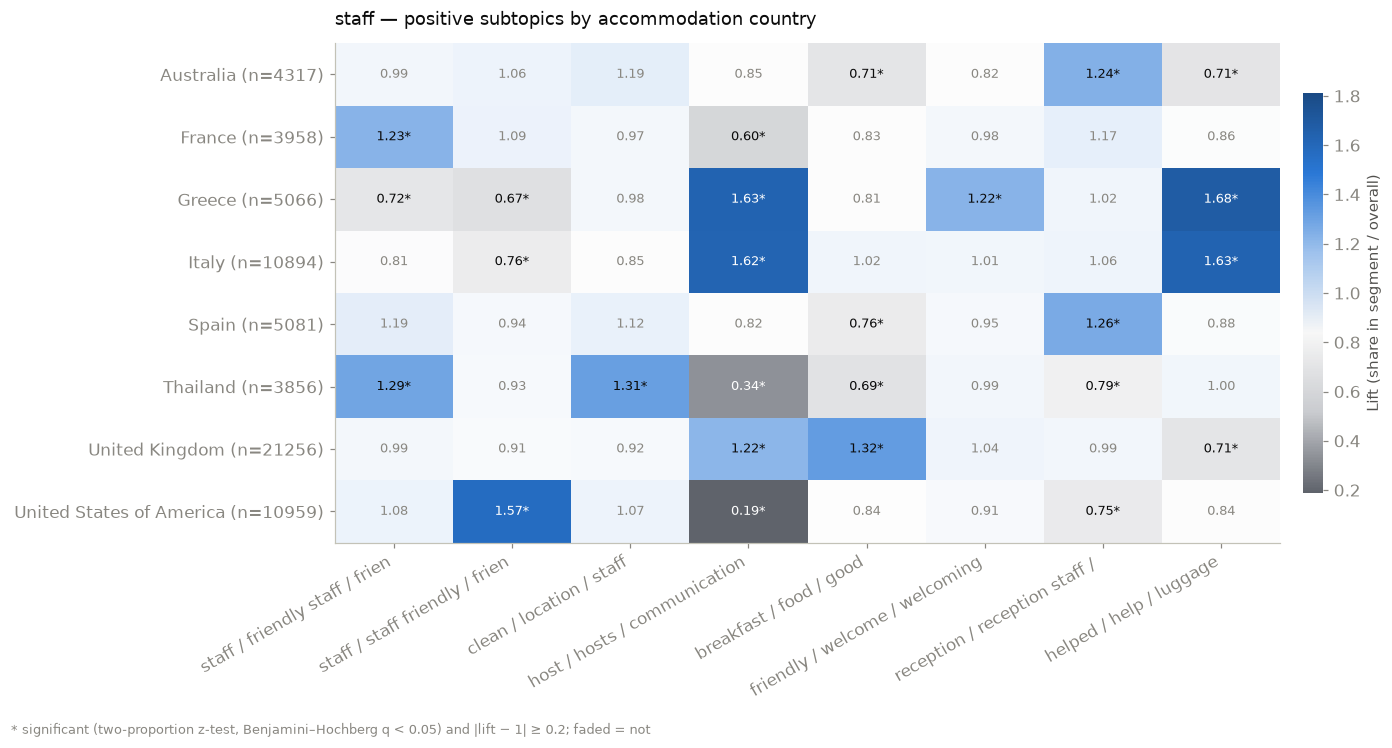

In [13]:
for aspect in MAIN_ASPECTS[:3]:
    for segment in ["accommodation_type", "accommodation_country"]:
        lift = tm.segment_table(assignments, subset, aspect, segment, min_count=50, top_segments=8)
        if lift.empty:
            continue
        long = tm.segment_long_table(lift)
        ev.save_table(long, f"05_{TAG}_map_{aspect}_by_{segment}")
        display(long[long["notable"]].head(8))
        tm.plot_segment_heatmap(lift, f"{aspect.replace('_', ' ')} — {SENTIMENT} subtopics by {segment.replace('_', ' ')}",
                                save_as=f"05_{TAG}_map_{aspect}_by_{segment}", sentiment=SENTIMENT)
        plt.show()

## 6. Kézi ellenőrzés / Manual check

HU: Témánként 20 véletlen mondat Excelben; a `fits` oszlopba 1 (illik a témához) vagy 0 kerül. Az első futás
exportál, a kitöltés után a második futás kiszámolja a témánkénti pontosságot. (Kb. 1–2 óra a nagyobb aspektusokra.)
EN: 20 random sentences per topic in Excel; put 1 (fits the topic) or 0 into the `fits` column. The first run exports,
after filling it in the second run computes the per-topic precision. (About 1–2 hours for the larger aspects.)

In [14]:
check_file = PATHS.annotation / f"topic_check_{TAG}.xlsx"
if not check_file.exists():
    top_aspects = MAIN_ASPECTS[:4]
    tm.export_topic_check(topic_table[topic_table["aspect"].isin(top_aspects)],
                          assignments[assignments["aspect"].isin(top_aspects)], subset,
                          filename=check_file.name)
    print("Exported — fill in the 'fits' column, then re-run this cell.")
else:
    precision = tm.evaluate_topic_check(check_file.name)
    display(precision); ev.save_table(precision, f"05_{TAG}_topic_precision")

21:30:14 | INFO    | src.topic_modeling | Topic check exported: C:\Users\seszt\Documents\BCE\7_felev\Szakdolgozat\THESIS\CODE\data\annotation\topic_check_positive_full2.xlsx (800 sentences)


Exported — fill in the 'fits' column, then re-run this cell.


---
## Összefoglalás / Summary

| Kimenet / Output | Mire jó? / Purpose |
|---|---|
| `05_aspect_keyword_vs_model` (tábla + ábra) | **2/a mérése:** tanult modell vs. kulcsszólista, emberi címkén |
| `05_aspect_model_test_report` | aspektusonkénti precision / recall / F1 |
| `05_aspect_sentiment_model` | aspektus × szentiment a tanult aspektusokkal |
| `05_<sentiment>_<verzió>_removed_non_complaints` | kiszűrt nem-panasz egységek („nothing”, „all good”) |
| `05_<sentiment>_<verzió>_granularity_sweep` | az altéma-finomság (fürtméret × összevonás) választásának indoklása |
| `05_<sentiment>_<verzió>_subtopics` + `_subtopics_by_aspect.png` | **2/b:** altémák aspektusonként |
| `05_<sentiment>_<verzió>_subtopic_quality`, `_stability` | koherencia, diverzitás, stabilitás |
| `05_<sentiment>_<verzió>_map_*` | **panasztérkép** szegmensenként (a 8 legnagyobb altéma; db, lift, q, szignifikáns, jelentős) |
| `05_<sentiment>_<verzió>_topic_precision` | kézi ellenőrzés: témánkénti pontosság |

HU: A `<verzió>` = `CFG.topic_version` (most `v5`). A régebbi, verzió nélküli `05_negative_*` fájlok a v1 futás
eredményei — a dolgozat 3.4 fejezetében az előtte–utána összevetéshez hasznosak.
EN: `<verzió>` = `CFG.topic_version` (now `v5`). The older `05_negative_*` files without a version are the results of
run v1 — useful for the before/after comparison in chapter 3.4.